In [9]:
import pandas as pd

url = "https://raw.githubusercontent.com/Prodigy-InfoTech/data-science-datasets/main/Task%204/twitter_training.csv"

df = pd.read_csv(url, header=None)

df.columns = ["ID", "Entity", "Sentiment", "Tweet"]

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (74682, 4)

First 5 rows:


,ID,Entity,Sentiment,Tweet
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...



Column names:
['ID', 'Entity', 'Sentiment', 'Tweet']


In [10]:
# 1. Check dataset information
print("Dataset Information:")
df.info()

# 2. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Check duplicate rows
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

# 4. Check sentiment categories
print("\nSentiment Counts:")
print(df["Sentiment"].value_counts())

# 5. Check unique entities
print("\nNumber of Unique Entities:")
print(df["Entity"].nunique())

# 6. Check summary statistics
print("\nSummary Statistics:")
display(df.describe(include="all"))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74682 entries, 0 to 74681
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         74682 non-null  int64 
 1   Entity     74682 non-null  object
 2   Sentiment  74682 non-null  object
 3   Tweet      73996 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.3+ MB

Missing Values:
ID             0
Entity         0
Sentiment      0
Tweet        686
dtype: int64

Number of Duplicate Rows:
2700

Sentiment Counts:
Sentiment
Negative      22542
Positive      20832
Neutral       18318
Irrelevant    12990
Name: count, dtype: int64

Number of Unique Entities:
32

Summary Statistics:


,ID,Entity,Sentiment,Tweet
count,74682.000000,74682,74682,73996
unique,NaN,32,4,69491
top,NaN,Microsoft,Negative,"At the same time, despite the fact that there ..."
freq,NaN,2400,22542,172
mean,6432.586165,NaN,NaN,NaN
std,3740.427870,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN
25%,3195.000000,NaN,NaN,NaN
50%,6422.000000,NaN,NaN,NaN
75%,9601.000000,NaN,NaN,NaN


In [11]:

# Remove rows with missing sentiment labels or tweets
df = df.dropna(subset=["Sentiment", "Tweet"])

# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows with empty tweet text
df["Tweet"] = df["Tweet"].astype(str).str.strip()
df = df[df["Tweet"] != ""]

# Standardize sentiment labels
df["Sentiment"] = df["Sentiment"].str.strip().str.title()

print("Dataset shape after cleaning:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nSentiment counts after cleaning:")
print(df["Sentiment"].value_counts())


Dataset shape after cleaning: (71484, 4)

Missing values after cleaning:
ID           0
Entity       0
Sentiment    0
Tweet        0
dtype: int64

Sentiment counts after cleaning:
Sentiment
Negative      21652
Positive      19677
Neutral       17651
Irrelevant    12504
Name: count, dtype: int64


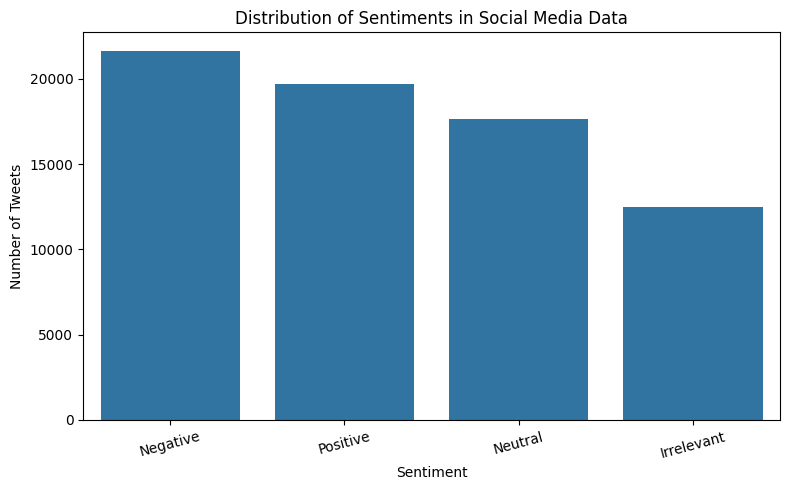

In [12]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Sentiment",
    order=df["Sentiment"].value_counts().index
)

plt.title("Distribution of Sentiments in Social Media Data")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


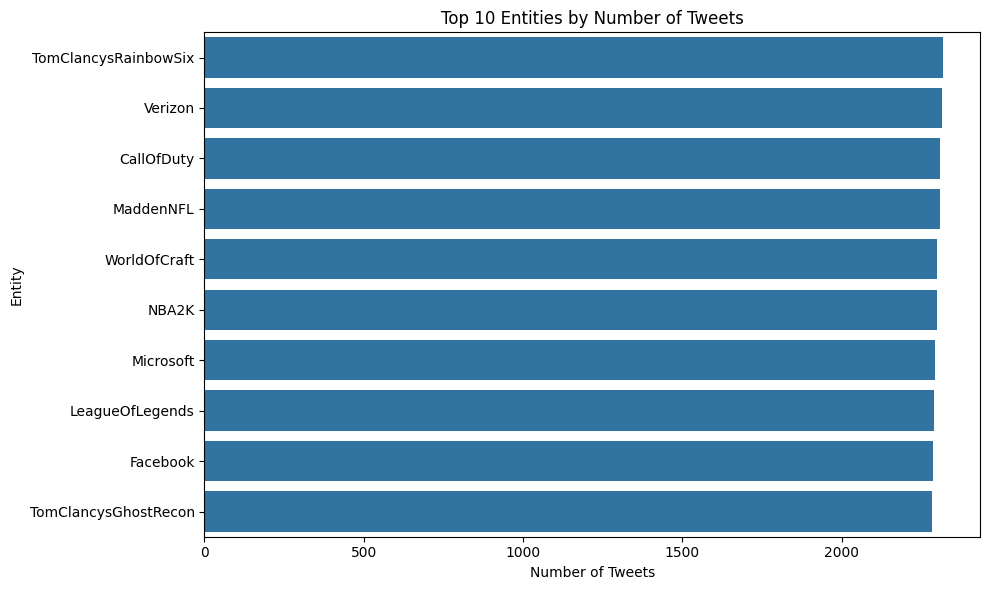

In [13]:

# Count tweets for each entity and select the top 10
top_entities = df["Entity"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_entities.values, y=top_entities.index)

plt.title("Top 10 Entities by Number of Tweets")
plt.xlabel("Number of Tweets")
plt.ylabel("Entity")
plt.tight_layout()
plt.show()


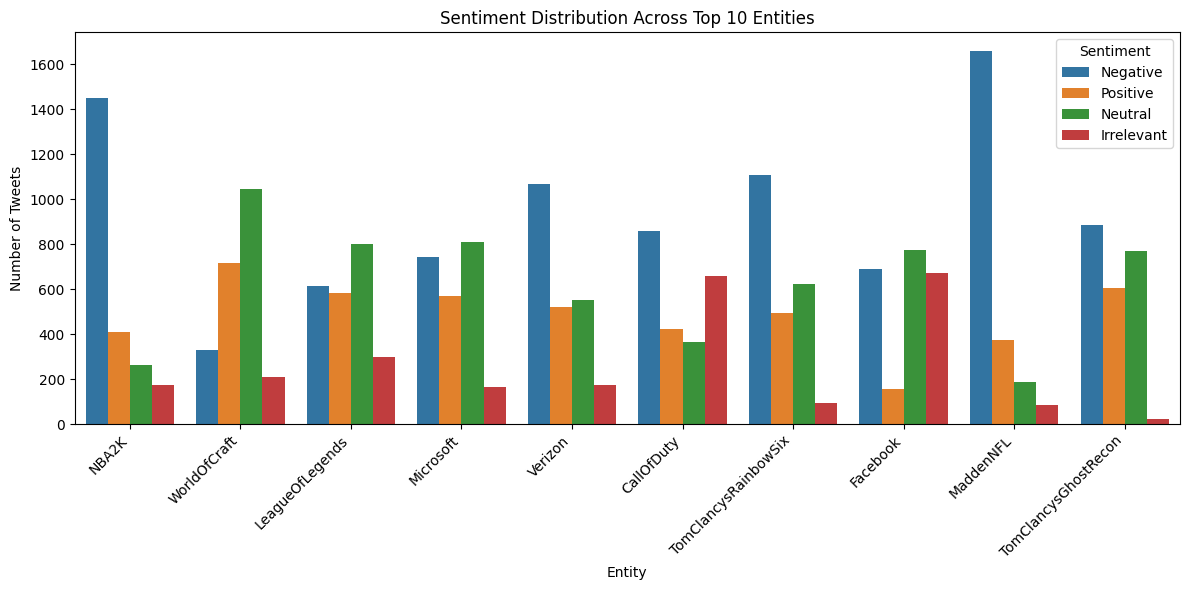

In [14]:

top_entity_names = top_entities.index

entity_sentiment = df[df["Entity"].isin(top_entity_names)]

plt.figure(figsize=(12, 6))
sns.countplot(
    data=entity_sentiment,
    x="Entity",
    hue="Sentiment"
)

plt.title("Sentiment Distribution Across Top 10 Entities")
plt.xlabel("Entity")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()


In [15]:

# Count and calculate the percentage of each sentiment
sentiment_counts = df["Sentiment"].value_counts()
sentiment_percentages = (
    df["Sentiment"].value_counts(normalize=True) * 100
)

sentiment_summary = pd.DataFrame({
    "Count": sentiment_counts,
    "Percentage": sentiment_percentages.round(2)
})

display(sentiment_summary)

print("Most common sentiment:", sentiment_counts.idxmax())
print("Least common sentiment:", sentiment_counts.idxmin())


,Count,Percentage
Sentiment,,
Negative,21652,30.29
Positive,19677,27.53
Neutral,17651,24.69
Irrelevant,12504,17.49


Most common sentiment: Negative
Least common sentiment: Irrelevant


## Conclusion

In this project, social media sentiment data was analyzed using Python, Pandas, Matplotlib, and Seaborn. The dataset was cleaned by removing missing values, duplicate records, and empty tweets.

Three visualizations were created to explore sentiment distribution, identify the top 10 entities by tweet count, and compare sentiment patterns across these entities.

The analysis showed that **Negative sentiment was the most common category, accounting for 30.29% of the cleaned dataset**, followed by Positive sentiment (27.53%) and Neutral sentiment (24.69%). Irrelevant sentiment was the least common category at 17.49%.

This project demonstrated how data analysis and visualization can help identify sentiment patterns and explore public opinions about different topics and brands.
